# ENGE707 Kaggle Competition: Group-Aware Validation Split

## Near-Duplicate and Validation-Reliability Experiment

This notebook strengthens the validation procedure without training a model. It:

1. computes perceptual hashes for every labelled image;
2. identifies visually similar files that may be resized or recompressed copies;
3. joins related same-class images into connected groups;
4. creates a reproducible, class-stratified 80/20 split using those groups;
5. verifies that no identified same-class near-duplicate pair crosses the new boundary; and
6. compares the original and group-aware splits.

The original dataset, original split, best model, and Kaggle submission remain unchanged. The current checkpoint is not evaluated on the new split because it has already trained on many images that may move into the new validation subset.

## 1. Import the Required Libraries

Pillow loads the images, SciPy calculates a perceptual hash from low-frequency image information, and scikit-learn creates the grouped stratified split.

In [1]:
# Imports the libraries used to find visually similar training images
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
import json
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold

## 2. Locate the Project Files

The notebook can run locally or on Kaggle. Kaggle file discovery stops if an artifact is ambiguous instead of silently selecting an unknown copy.

In [2]:
# Finds the labelled images original splits and output folders
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_unique_kaggle_file(filename, preferred_text=None):
    """Return one unambiguous Kaggle input file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if preferred_text:
        preferred = [
            path for path in matches
            if preferred_text.lower() in str(path).lower()
        ]
        if preferred:
            matches = preferred

    if len(matches) != 1:
        text = "\n".join(str(path) for path in matches)
        raise RuntimeError(
            f"Expected exactly one {filename}, found {len(matches)}.\n{text}"
        )
    return matches[0]


def find_unique_image_directory(filename, split_name):
    """Locate one image directory containing the probe file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    matches = [
        path for path in matches
        if split_name.lower() in {part.lower() for part in path.parent.parts}
    ]
    directories = sorted({path.parent for path in matches})
    if len(directories) != 1:
        text = "\n".join(str(path) for path in directories)
        raise RuntimeError(
            f"Expected one {split_name} directory, found "
            f"{len(directories)}.\n{text}"
        )
    return directories[0]


if RUNNING_ON_KAGGLE:
    PROJECT_ROOT = Path("/kaggle/working")
    TRAIN_LABELS_PATH = find_unique_kaggle_file("train_labels.csv")
    ORIGINAL_TRAIN_SPLIT_PATH = find_unique_kaggle_file(
        "train_split.csv",
        preferred_text="facial-feature-project-artifacts",
    )
    ORIGINAL_VALIDATION_SPLIT_PATH = find_unique_kaggle_file(
        "validation_split.csv",
        preferred_text="facial-feature-project-artifacts",
    )
    IMAGE_PROPERTIES_PATH = find_unique_kaggle_file(
        "image_properties.csv",
        preferred_text="facial-feature-project-artifacts",
    )
    PREPROCESSING_CONFIG_PATH = find_unique_kaggle_file(
        "preprocessing_config.json",
        preferred_text="facial-feature-project-artifacts",
    )

    probe = pd.read_csv(
        TRAIN_LABELS_PATH,
        dtype={"image_id": "string"},
        nrows=1,
    ).iloc[0]["image_id"]
    probe_filename = f"{int(probe):05d}.jpg"
    TRAIN_IMAGE_DIR = find_unique_image_directory(probe_filename, "train")
else:
    possible_roots = [Path.cwd(), Path.cwd().parent]
    PROJECT_ROOT = next(
        (
            folder for folder in possible_roots
            if (folder / "data" / "train_labels.csv").exists()
        ),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError("The project root could not be located.")

    TRAIN_LABELS_PATH = PROJECT_ROOT / "data" / "train_labels.csv"
    TRAIN_IMAGE_DIR = PROJECT_ROOT / "data" / "train" / "train"
    ORIGINAL_TRAIN_SPLIT_PATH = PROJECT_ROOT / "splits" / "train_split.csv"
    ORIGINAL_VALIDATION_SPLIT_PATH = (
        PROJECT_ROOT / "splits" / "validation_split.csv"
    )
    IMAGE_PROPERTIES_PATH = (
        PROJECT_ROOT
        / "outputs"
        / "quality_checks"
        / "image_properties.csv"
    )
    PREPROCESSING_CONFIG_PATH = (
        PROJECT_ROOT
        / "outputs"
        / "preprocessing"
        / "preprocessing_config.json"
    )

GROUPED_SPLIT_DIR = PROJECT_ROOT / "splits" / "group_aware"
AUDIT_DIR = PROJECT_ROOT / "outputs" / "split_audit"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

GROUPED_SPLIT_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Environment:", "Kaggle" if RUNNING_ON_KAGGLE else "Local")
print("Training images:", TRAIN_IMAGE_DIR)
print("Original validation split:", ORIGINAL_VALIDATION_SPLIT_PATH)

Environment: Local
Training images: /Users/fatehbhular/ENSE707-Kaggle-Competition/data/train/train
Original validation split: /Users/fatehbhular/ENSE707-Kaggle-Competition/splits/validation_split.csv


## 3. Load and Verify the Labelled Data

The class names are read from the original labels. Existing split membership is retained only for comparison; it does not control the new split.

In [3]:
# Loads the labels and settings used for the similarity audit
RANDOM_SEED = 42
NUMBER_OF_FOLDS = 5
PERCEPTUAL_DISTANCE_THRESHOLD = 6

labels = pd.read_csv(
    TRAIN_LABELS_PATH,
    dtype={"image_id": "string", "class": "string"},
)
labels["filename"] = labels["image_id"].map(
    lambda image_id: f"{int(image_id):05d}.jpg"
)

original_train = pd.read_csv(
    ORIGINAL_TRAIN_SPLIT_PATH,
    dtype={"image_id": "string", "filename": "string"},
)
original_validation = pd.read_csv(
    ORIGINAL_VALIDATION_SPLIT_PATH,
    dtype={"image_id": "string", "filename": "string"},
)

properties = pd.read_csv(
    IMAGE_PROPERTIES_PATH,
    dtype={"filename": "string", "split": "string"},
)
properties = properties[properties["split"] == "train"].copy()

with open(PREPROCESSING_CONFIG_PATH) as config_file:
    preprocessing_config = json.load(config_file)
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])

if len(labels) != 63660:
    raise ValueError(f"Expected 63,660 labels, found {len(labels):,}.")
if labels["image_id"].duplicated().any():
    raise ValueError("Duplicate image IDs were found in train_labels.csv.")
if set(original_train["image_id"]) & set(original_validation["image_id"]):
    raise ValueError("The original split contains overlapping image IDs.")

if set(labels["class"]) != set(CLASS_NAMES):
    raise ValueError(
        "The label classes do not match preprocessing_config.json."
    )
print("Labelled images:", f"{len(labels):,}")
print("Original training images:", f"{len(original_train):,}")
print("Original validation images:", f"{len(original_validation):,}")
print("Classes:", CLASS_NAMES)

Labelled images: 63,660
Original training images: 50,928
Original validation images: 12,732
Classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']


## 4. Calculate Perceptual Hashes

A perceptual hash represents the broad visual structure of an image rather than its exact file bytes. Images can therefore receive similar hashes after resizing or JPEG recompression.

The hash is used only to form validation groups. It is not an input feature for the classifier.

In [4]:
# Calculates a compact visual fingerprint for each labelled image
def calculate_perceptual_hash(item):
    """Return a 64-bit perceptual hash for one image."""
    filename, image_path = item
    with Image.open(image_path) as image:
        grayscale = image.convert("L").resize(
            (32, 32),
            Image.Resampling.LANCZOS,
        )
        pixels = np.asarray(grayscale, dtype=np.float32)

    coefficients = dctn(pixels, type=2, norm="ortho")[:8, :8]
    median = np.median(coefficients.ravel()[1:])
    bits = (coefficients > median).ravel()

    hash_value = 0
    for bit in bits:
        hash_value = (hash_value << 1) | int(bit)
    return filename, hash_value


hash_start = time.perf_counter()
hash_inputs = [
    (row.filename, TRAIN_IMAGE_DIR / row.filename)
    for row in labels.itertuples(index=False)
]

workers = 8 if not RUNNING_ON_KAGGLE else 4
with ThreadPoolExecutor(max_workers=workers) as executor:
    hash_rows = list(executor.map(
        calculate_perceptual_hash,
        hash_inputs,
        chunksize=64,
    ))

hash_seconds = time.perf_counter() - hash_start
hashes = pd.DataFrame(hash_rows, columns=["filename", "perceptual_hash"])
labels = labels.merge(hashes, on="filename", how="left", validate="one_to_one")

if labels["perceptual_hash"].isna().any():
    raise ValueError("At least one perceptual hash is missing.")

# Saves the table as a CSV file for later notebooks or report evidence
hashes.assign(
    perceptual_hash=lambda frame: frame["perceptual_hash"].map(
        lambda value: f"{int(value):016x}"
    )
).to_csv(AUDIT_DIR / "perceptual_hashes.csv", index=False)

print("Images hashed:", f"{len(hashes):,}")
print("Hashing time:", f"{hash_seconds:.1f} seconds")

Images hashed: 63,660
Hashing time: 10.7 seconds


## 5. Find Near-Duplicate Candidate Pairs

Two hashes are treated as near-duplicates when their Hamming distance is at most 6 bits out of 64. The search uses eight hash chunks to avoid comparing every possible pair.

Only same-class pairs are automatically grouped. Cross-class visual matches are saved separately for manual inspection because they may be either ambiguous images or false perceptual matches.

In [5]:
# Finds candidate near duplicates by comparing visual fingerprints
class DisjointSet:
    """Maintain connected components of related filenames."""

    def __init__(self, size):
        self.parent = list(range(size))
        self.component_size = [1] * size

    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item

    def union(self, first, second):
        first_root = self.find(first)
        second_root = self.find(second)
        if first_root == second_root:
            return
        if self.component_size[first_root] < self.component_size[second_root]:
            first_root, second_root = second_root, first_root
        self.parent[second_root] = first_root
        self.component_size[first_root] += self.component_size[second_root]


hash_values = labels["perceptual_hash"].astype("uint64").tolist()
class_values = labels["class"].tolist()
filename_values = labels["filename"].tolist()
disjoint_set = DisjointSet(len(labels))

# Hamming distance <= 6 guarantees that at least two of eight
# Corresponding 8-bit chunks are identical
buckets = {}
accepted_pairs = {}
candidate_comparisons = 0
pair_start = time.perf_counter()

for current_index, current_hash in enumerate(hash_values):
    chunks = tuple(
        (int(current_hash) >> (8 * position)) & 0xFF
        for position in range(8)
    )
    candidate_indices = set()

    for first_position, second_position in combinations(range(8), 2):
        key = (
            first_position,
            second_position,
            chunks[first_position],
            chunks[second_position],
        )
        candidate_indices.update(buckets.get(key, ()))

    for previous_index in candidate_indices:
        candidate_comparisons += 1
        distance = (
            int(current_hash) ^ int(hash_values[previous_index])
        ).bit_count()
        if distance <= PERCEPTUAL_DISTANCE_THRESHOLD:
            pair_key = (previous_index, current_index)
            accepted_pairs[pair_key] = distance
            if class_values[previous_index] == class_values[current_index]:
                disjoint_set.union(previous_index, current_index)

    for first_position, second_position in combinations(range(8), 2):
        key = (
            first_position,
            second_position,
            chunks[first_position],
            chunks[second_position],
        )
        buckets.setdefault(key, []).append(current_index)

pair_seconds = time.perf_counter() - pair_start

pair_rows = []
for (first_index, second_index), distance in accepted_pairs.items():
    pair_rows.append(
        {
            "filename_1": filename_values[first_index],
            "class_1": class_values[first_index],
            "filename_2": filename_values[second_index],
            "class_2": class_values[second_index],
            "hamming_distance": distance,
            "same_class": (
                class_values[first_index] == class_values[second_index]
            ),
        }
    )

near_duplicate_pairs = pd.DataFrame(pair_rows)
if len(near_duplicate_pairs) == 0:
    near_duplicate_pairs = pd.DataFrame(
        columns=[
            "filename_1",
            "class_1",
            "filename_2",
            "class_2",
            "hamming_distance",
            "same_class",
        ]
    )

# Saves the table as a CSV file for later notebooks or report evidence
near_duplicate_pairs.to_csv(
    AUDIT_DIR / "perceptual_near_duplicate_pairs.csv",
    index=False,
)
# Saves the table as a CSV file for later notebooks or report evidence
near_duplicate_pairs[~near_duplicate_pairs["same_class"]].to_csv(
    AUDIT_DIR / "cross_class_perceptual_matches.csv",
    index=False,
)

print("Candidate comparisons:", f"{candidate_comparisons:,}")
print("Near-duplicate pairs:", f"{len(near_duplicate_pairs):,}")
print(
    "Same-class pairs:",
    f"{near_duplicate_pairs['same_class'].sum():,}",
)
print(
    "Cross-class matches requiring review:",
    f"{(~near_duplicate_pairs['same_class']).sum():,}",
)
print("Pair-search time:", f"{pair_seconds:.1f} seconds")

Candidate comparisons: 2,439,989
Near-duplicate pairs: 1,170
Same-class pairs: 1,151
Cross-class matches requiring review: 19
Pair-search time: 2.0 seconds


## 6. Create Connected Group IDs

If image A resembles B and B resembles C, all three belong to one connected group even when A and C are slightly farther apart. This prevents a chain of related images from crossing the split.

In [6]:
# Groups connected same class matches under shared identifiers
component_members = {}
for index in range(len(labels)):
    root = disjoint_set.find(index)
    component_members.setdefault(root, []).append(index)

component_rows = []
group_id_by_index = {}
for root, members in component_members.items():
    member_filenames = sorted(filename_values[index] for index in members)
    if len(members) > 1:
        group_id = f"perceptual_{Path(member_filenames[0]).stem}"
    else:
        group_id = f"unique_{Path(member_filenames[0]).stem}"

    for index in members:
        group_id_by_index[index] = group_id
        component_rows.append(
            {
                "group_id": group_id,
                "filename": filename_values[index],
                "class": class_values[index],
                "group_size": len(members),
            }
        )

labels["group_id"] = [
    group_id_by_index[index] for index in range(len(labels))
]
components = pd.DataFrame(component_rows)
# Saves the table as a CSV file for later notebooks or report evidence
components.to_csv(
    AUDIT_DIR / "perceptual_duplicate_groups.csv",
    index=False,
)

group_sizes = components.groupby("group_id").size()
print("Total groups:", f"{len(group_sizes):,}")
print("Multi-image groups:", f"{(group_sizes > 1).sum():,}")
print(
    "Images in multi-image groups:",
    f"{group_sizes[group_sizes > 1].sum():,}",
)
print("Largest group:", int(group_sizes.max()))

Total groups: 62,884
Multi-image groups: 506
Images in multi-image groups: 1,282
Largest group: 128


## 7. Measure Leakage Risk in the Original Split

This check counts detected same-class near-duplicate pairs that were separated by the original train/validation split. It measures the specific leakage that the new grouping method addresses.

In [7]:
# Counts near duplicate pairs that cross the original split
original_membership = {
    **{filename: "train" for filename in original_train["filename"]},
    **{
        filename: "validation"
        for filename in original_validation["filename"]
    },
}

if len(near_duplicate_pairs) > 0:
    near_duplicate_pairs["original_subset_1"] = (
        near_duplicate_pairs["filename_1"].map(original_membership)
    )
    near_duplicate_pairs["original_subset_2"] = (
        near_duplicate_pairs["filename_2"].map(original_membership)
    )
    near_duplicate_pairs["crosses_original_split"] = (
        near_duplicate_pairs["original_subset_1"]
        != near_duplicate_pairs["original_subset_2"]
    )
else:
    near_duplicate_pairs["original_subset_1"] = pd.Series(dtype="string")
    near_duplicate_pairs["original_subset_2"] = pd.Series(dtype="string")
    near_duplicate_pairs["crosses_original_split"] = pd.Series(dtype=bool)

same_class_pairs = near_duplicate_pairs[
    near_duplicate_pairs["same_class"]
].copy()
crossing_original = same_class_pairs[
    same_class_pairs["crosses_original_split"]
].copy()
# Saves the table as a CSV file for later notebooks or report evidence
crossing_original.to_csv(
    AUDIT_DIR / "near_duplicates_crossing_original_split.csv",
    index=False,
)

validation_near_duplicate_filenames = set(
    crossing_original.loc[
        crossing_original["original_subset_1"] == "validation",
        "filename_1",
    ]
) | set(
    crossing_original.loc[
        crossing_original["original_subset_2"] == "validation",
        "filename_2",
    ]
)

print(
    "Same-class pairs crossing the original split:",
    f"{len(crossing_original):,}",
)
print(
    "Original validation images involved:",
    f"{len(validation_near_duplicate_filenames):,}",
)
print(
    "Share of original validation:",
    f"{len(validation_near_duplicate_filenames) / len(original_validation):.2%}",
)

Same-class pairs crossing the original split: 398
Original validation images involved: 215
Share of original validation: 1.69%


## 8. Create the Group-Aware 80/20 Split

`StratifiedGroupKFold` keeps the class proportions similar while assigning each connected image group wholly to training or validation. Five folds produce an approximately 80/20 division.

In [8]:
# Creates new subsets while keeping detected groups together
splitter = StratifiedGroupKFold(
    n_splits=NUMBER_OF_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

training_indices, validation_indices = next(
    splitter.split(
        X=labels["filename"],
        y=labels["class"],
        groups=labels["group_id"],
    )
)

grouped_train = (
    labels.iloc[training_indices]
    .copy()
    .reset_index(drop=True)
)
grouped_validation = (
    labels.iloc[validation_indices]
    .copy()
    .reset_index(drop=True)
)

grouped_train["label_index"] = grouped_train["class"].map(
    CLASS_TO_INDEX
)
grouped_validation["label_index"] = grouped_validation["class"].map(
    CLASS_TO_INDEX
)

# Saves the table as a CSV file for later notebooks or report evidence
grouped_train.to_csv(
    GROUPED_SPLIT_DIR / "train_split_group_aware.csv",
    index=False,
)
# Saves the table as a CSV file for later notebooks or report evidence
grouped_validation.to_csv(
    GROUPED_SPLIT_DIR / "validation_split_group_aware.csv",
    index=False,
)

print("Group-aware training images:", f"{len(grouped_train):,}")
print("Group-aware validation images:", f"{len(grouped_validation):,}")
print(
    "Validation percentage:",
    f"{len(grouped_validation) / len(labels):.2%}",
)

Group-aware training images: 50,928
Group-aware validation images: 12,732
Validation percentage: 20.00%


## 9. Verify Leakage Prevention and Stratification

The checks confirm that every image appears exactly once, group IDs do not cross the split, all same-class perceptual pairs stay together, and class proportions remain close to the complete labelled dataset.

In [9]:
# Checks group separation and class proportions in the new split
train_ids = set(grouped_train["image_id"])
validation_ids = set(grouped_validation["image_id"])
train_groups = set(grouped_train["group_id"])
validation_groups = set(grouped_validation["group_id"])

new_membership = {
    **{filename: "train" for filename in grouped_train["filename"]},
    **{
        filename: "validation"
        for filename in grouped_validation["filename"]
    },
}

if len(same_class_pairs) > 0:
    pair_crosses_new_split = (
        same_class_pairs["filename_1"].map(new_membership)
        != same_class_pairs["filename_2"].map(new_membership)
    )
    near_pairs_crossing_new_split = int(pair_crosses_new_split.sum())
else:
    near_pairs_crossing_new_split = 0

complete_distribution = labels["class"].value_counts(normalize=True)
train_distribution = grouped_train["class"].value_counts(normalize=True)
validation_distribution = grouped_validation["class"].value_counts(
    normalize=True
)
maximum_class_difference = float(
    (validation_distribution - complete_distribution).abs().max()
)

split_checks = pd.DataFrame(
    {
        "check": [
            "Training and validation IDs do not overlap",
            "Every labelled image appears exactly once",
            "Connected group IDs do not overlap",
            "No same-class near-duplicate pair crosses the split",
            "Validation is approximately 20%",
            "Maximum class-proportion difference is below 0.5%",
        ],
        "result": [
            len(train_ids & validation_ids) == 0,
            len(train_ids | validation_ids) == len(labels),
            len(train_groups & validation_groups) == 0,
            near_pairs_crossing_new_split == 0,
            abs(len(grouped_validation) / len(labels) - 0.20) < 0.01,
            maximum_class_difference < 0.005,
        ],
        "expected": [True] * 6,
    }
)
# Saves the table as a CSV file for later notebooks or report evidence
split_checks.to_csv(
    AUDIT_DIR / "group_aware_split_checks.csv",
    index=False,
)
display(split_checks)
assert split_checks["result"].all()

print(
    "Maximum class-proportion difference:",
    f"{maximum_class_difference:.3%}",
)

,check,result,expected
0,Training and validation IDs do not overlap,True,True
1,Every labelled image appears exactly once,True,True
2,Connected group IDs do not overlap,True,True
3,No same-class near-duplicate pair crosses the ...,True,True
4,Validation is approximately 20%,True,True
5,Maximum class-proportion difference is below 0.5%,True,True


Maximum class-proportion difference: 0.005%


## 10. Compare Class and Image-Property Distributions

This comparison checks whether the new validation subset remains representative of the labelled data. It also contrasts both validation splits with the unseen test image geometry recorded during dataset exploration.

In [10]:
# Compares class counts image sizes and other properties between subsets
def subset_properties(split_frame, subset_name):
    merged = split_frame[["filename"]].merge(
        properties,
        on="filename",
        how="left",
        validate="one_to_one",
    )
    width = merged["width"].to_numpy()
    height = merged["height"].to_numpy()
    largest = np.maximum(width, height)
    shortest = np.minimum(width, height)
    padding_fraction = 1 - (width * height) / (largest * largest)
    return {
        "subset": subset_name,
        "images": len(merged),
        "square_percentage": float((width == height).mean() * 100),
        "short_side_below_64_percentage": float(
            (shortest < 64).mean() * 100
        ),
        "padding_above_40_percentage": float(
            (padding_fraction > 0.40).mean() * 100
        ),
        "median_brightness": float(merged["brightness"].median()),
        "median_sharpness": float(merged["sharpness_score"].median()),
    }


test_properties = pd.read_csv(
    IMAGE_PROPERTIES_PATH,
    dtype={"filename": "string", "split": "string"},
)
test_properties = test_properties[test_properties["split"] == "test"]
test_width = test_properties["width"].to_numpy()
test_height = test_properties["height"].to_numpy()
test_largest = np.maximum(test_width, test_height)
test_shortest = np.minimum(test_width, test_height)
test_padding = 1 - (
    test_width * test_height
) / (test_largest * test_largest)

property_comparison = pd.DataFrame(
    [
        subset_properties(original_validation, "Original validation"),
        subset_properties(grouped_validation, "Group-aware validation"),
        {
            "subset": "Kaggle test",
            "images": len(test_properties),
            "square_percentage": float(
                (test_width == test_height).mean() * 100
            ),
            "short_side_below_64_percentage": float(
                (test_shortest < 64).mean() * 100
            ),
            "padding_above_40_percentage": float(
                (test_padding > 0.40).mean() * 100
            ),
            "median_brightness": float(
                test_properties["brightness"].median()
            ),
            "median_sharpness": float(
                test_properties["sharpness_score"].median()
            ),
        },
    ]
)
# Saves the table as a CSV file for later notebooks or report evidence
property_comparison.to_csv(
    AUDIT_DIR / "split_property_comparison.csv",
    index=False,
)

distribution_rows = []
for subset_name, frame in [
    ("Complete labelled data", labels),
    ("Original validation", original_validation),
    ("Group-aware validation", grouped_validation),
]:
    counts = frame["class"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    for class_name, count in counts.items():
        distribution_rows.append(
            {
                "subset": subset_name,
                "class": class_name,
                "images": int(count),
                "percentage": float(count / len(frame) * 100),
            }
        )

distribution_comparison = pd.DataFrame(distribution_rows)
# Saves the table as a CSV file for later notebooks or report evidence
distribution_comparison.to_csv(
    AUDIT_DIR / "group_aware_class_distribution.csv",
    index=False,
)

display(property_comparison.round(2))
display(distribution_comparison.pivot(
    index="class",
    columns="subset",
    values="percentage",
).round(2))

,subset,images,square_percentage,short_side_below_64_percentage,padding_above_40_percentage,median_brightness,median_sharpness
0,Original validation,12732,65.52,37.09,0.38,111.22,165.50
1,Group-aware validation,12732,65.42,37.28,0.48,111.26,164.46
2,Kaggle test,29443,32.85,40.41,1.21,111.96,164.75


subset,Complete labelled data,Group-aware validation,Original validation
class,,,
CatEye,21.81,21.81,21.81
CatFace,10.90,10.90,10.91
CatMouth,10.90,10.91,10.90
CatNose,10.90,10.90,10.90
DogEye,18.19,18.19,18.19
DogFace,9.10,9.10,9.10
DogMouth,9.10,9.10,9.10
DogNose,9.10,9.10,9.10


## 11. Create Report Figures

The first figure compares class proportions. The second compares geometry indicators that revealed a difference between labelled and Kaggle test images.

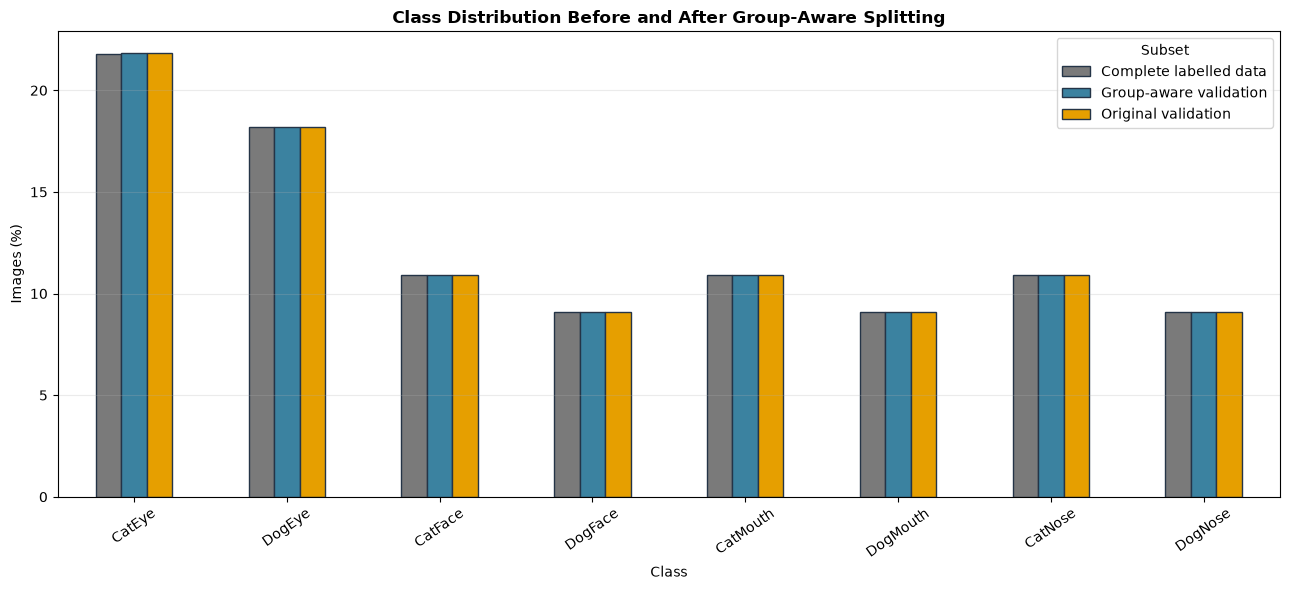

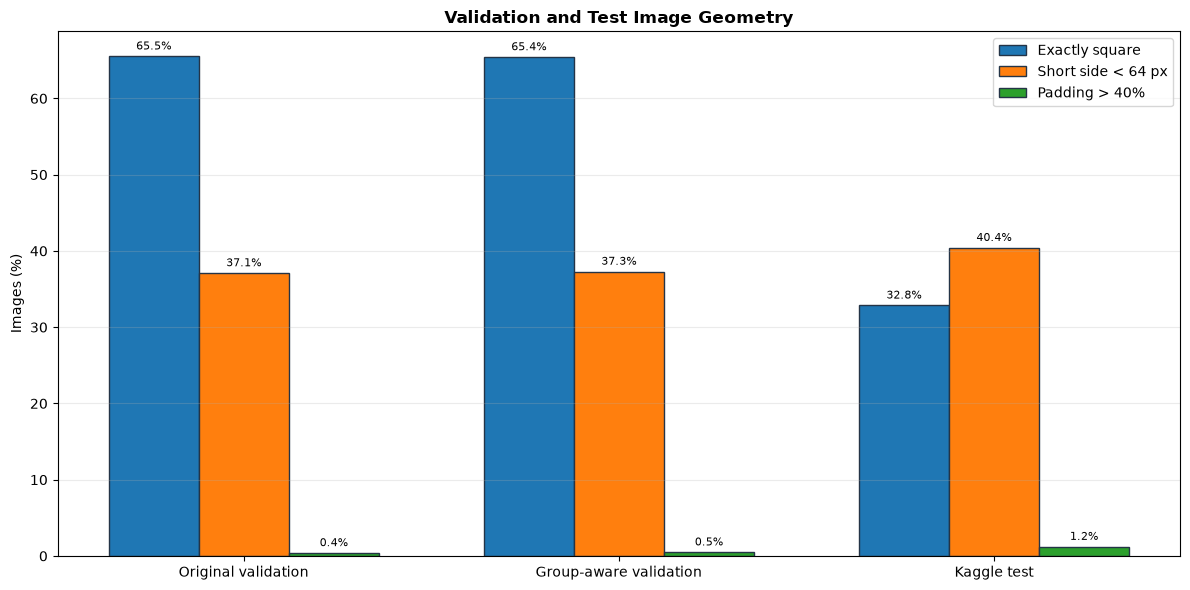

Class figure: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_24_group_aware_class_distribution.png
Geometry figure: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/figures/figure_25_split_geometry_comparison.png


In [11]:
# Saves figures showing the new split and image properties
class_figure_path = FIGURE_DIR / "figure_24_group_aware_class_distribution.png"
geometry_figure_path = FIGURE_DIR / "figure_25_split_geometry_comparison.png"

pivot = distribution_comparison.pivot(
    index="class",
    columns="subset",
    values="percentage",
).reindex(CLASS_NAMES)

axis = pivot.plot(
    kind="bar",
    figsize=(13, 6),
    color=["#7A7A7A", "#3B82A0", "#E69F00"],
    edgecolor="#243447",
)
axis.set_title("Class Distribution Before and After Group-Aware Splitting", weight="bold")
axis.set_ylabel("Images (%)")
axis.set_xlabel("Class")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
axis.legend(title="Subset")
plt.tight_layout()
# Saves the figure so it can be included in the report
plt.savefig(class_figure_path, dpi=300, bbox_inches="tight")
plt.show()

geometry_columns = [
    "square_percentage",
    "short_side_below_64_percentage",
    "padding_above_40_percentage",
]
geometry_labels = [
    "Exactly square",
    "Short side < 64 px",
    "Padding > 40%",
]
x_positions = np.arange(len(property_comparison))
bar_width = 0.24

fig, axis = plt.subplots(figsize=(12, 6))
for offset, (column, label) in enumerate(
    zip(geometry_columns, geometry_labels)
):
    bars = axis.bar(
        x_positions + (offset - 1) * bar_width,
        property_comparison[column],
        width=bar_width,
        label=label,
        edgecolor="#243447",
    )
    axis.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8)

axis.set_xticks(x_positions, property_comparison["subset"])
axis.set_ylabel("Images (%)")
axis.set_title("Validation and Test Image Geometry", weight="bold")
axis.grid(axis="y", alpha=0.25)
axis.legend()
fig.tight_layout()
# Saves the figure so it can be included in the report
fig.savefig(geometry_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Class figure:", class_figure_path)
print("Geometry figure:", geometry_figure_path)

## 12. Save the Audit Summary

The summary separates what this notebook proves from what still requires retraining. A lower score on the group-aware split cannot be measured using the old checkpoint because that checkpoint has already seen many of the new validation images.

In [12]:
# Saves the audit findings and final consistency checks
audit_summary = {
    "random_seed": RANDOM_SEED,
    "perceptual_hash": "64-bit DCT pHash",
    "perceptual_distance_threshold": PERCEPTUAL_DISTANCE_THRESHOLD,
    "cross_class_matches_grouped_automatically": False,
    "labelled_images": int(len(labels)),
    "near_duplicate_pairs": int(len(near_duplicate_pairs)),
    "same_class_near_duplicate_pairs": int(
        near_duplicate_pairs["same_class"].sum()
    ),
    "cross_class_matches_for_review": int(
        (~near_duplicate_pairs["same_class"]).sum()
    ),
    "same_class_pairs_crossing_original_split": int(
        len(crossing_original)
    ),
    "original_validation_images_in_crossing_pairs": int(
        len(validation_near_duplicate_filenames)
    ),
    "group_aware_training_images": int(len(grouped_train)),
    "group_aware_validation_images": int(len(grouped_validation)),
    "near_duplicate_pairs_crossing_new_split": int(
        near_pairs_crossing_new_split
    ),
    "maximum_class_proportion_difference": maximum_class_difference,
    "old_checkpoint_valid_on_new_split": False,
    "next_required_experiment": (
        "Retrain the unchanged ResNet18 baseline on the group-aware split"
    ),
}

summary_path = AUDIT_DIR / "group_aware_split_summary.json"
with open(summary_path, "w") as summary_file:
    json.dump(audit_summary, summary_file, indent=4)

print(json.dumps(audit_summary, indent=2))
print("Summary:", summary_path)

{
  "random_seed": 42,
  "perceptual_hash": "64-bit DCT pHash",
  "perceptual_distance_threshold": 6,
  "cross_class_matches_grouped_automatically": false,
  "labelled_images": 63660,
  "near_duplicate_pairs": 1170,
  "same_class_near_duplicate_pairs": 1151,
  "cross_class_matches_for_review": 19,
  "same_class_pairs_crossing_original_split": 398,
  "original_validation_images_in_crossing_pairs": 215,
  "group_aware_training_images": 50928,
  "group_aware_validation_images": 12732,
  "near_duplicate_pairs_crossing_new_split": 0,
  "maximum_class_proportion_difference": 4.712535344014723e-05,
  "old_checkpoint_valid_on_new_split": false,
  "next_required_experiment": "Retrain the unchanged ResNet18 baseline on the group-aware split"
}
Summary: /Users/fatehbhular/ENSE707-Kaggle-Competition/outputs/split_audit/group_aware_split_summary.json


## 13. Package the Split and Evidence

The package contains the new split and its audit evidence. It does not contain a trained model or Kaggle submission.

In [13]:
# Packages the new split files and supporting audit evidence
package_staging = PROJECT_ROOT / "group_aware_split_package"
if package_staging.exists():
    shutil.rmtree(package_staging)
package_staging.mkdir(parents=True)

for source in GROUPED_SPLIT_DIR.glob("*.csv"):
    shutil.copy2(source, package_staging / source.name)
for source in AUDIT_DIR.glob("*"):
    if source.is_file():
        shutil.copy2(source, package_staging / source.name)

package_path = shutil.make_archive(
    str(PROJECT_ROOT / "group_aware_split_results"),
    "zip",
    root_dir=package_staging,
)
shutil.rmtree(package_staging)

print("Results package:", package_path)
print("Training performed: False")
print("Original split modified: False")
print("Current model modified: False")

Results package: /Users/fatehbhular/ENSE707-Kaggle-Competition/group_aware_split_results.zip
Training performed: False
Original split modified: False
Current model modified: False
